<a href="https://colab.research.google.com/github/acardozo96/Proyecto-integrador-retail/blob/main/Proyecto_Integrador_EntregaFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset de Online Retail desde URL directa garantizada
url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/07_Visualization/Online_Retail/Online_Retail.csv"
df = pd.read_csv(url, encoding="latin1")

# Ver las primeras 5 filas
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [ ]:
# Inspeccionar tipos de datos y valores nulos
print("--- Información general del dataset ---")
df.info()

print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())

--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

--- Valores nulos por columna ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# 1. Eliminar filas con CustomerID nulo
df_clean = df.dropna(subset=['CustomerID']).copy()

# 2. Filtrar solo compras válidas (cantidad y precio mayores a 0)
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 3. Convertir CustomerID a entero y verificar dimensiones finales
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

print(f"Filas originales: {len(df)}")
print(f"Filas limpias para el modelo: {len(df_clean)}")
print(f"Cantidad de clientes únicos: {df_clean['CustomerID'].nunique()}")

Filas originales: 541909
Filas limpias para el modelo: 397884
Cantidad de clientes únicos: 4338


In [ ]:
# 1. Crear columna de Monto Total por fila
df_clean['TotalSum'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 2. Convertir InvoiceDate a formato datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 3. Definir fecha de referencia (un día después de la última compra registrada)
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# 4. Agrupar por CustomerID y calcular métricas RFM (CON DOS PUNTOS ':')
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSum': 'sum'
}).reset_index()

# Renombrar columnas
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# Mostrar resumen
print(rfm.head())


C:\Users\an-gi\AppData\Local\Temp\ipykernel_7600\1692291123.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


   CustomerID  Recency  Frequency  Monetary
0       12346      326          1  77183.60
1       12347        2          7   4310.00
2       12348       75          4   1797.24
3       12349       19          1   1757.55
4       12350      310          1    334.40


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Aplicar transformación logarítmica para reducir asimetría
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# 2. Escalar las variables (Media = 0, Desviación Estándar = 1)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convertir a DataFrame para facilitar su uso
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
print("--- Datos escalados y listos para K-Means ---")
rfm_scaled_df.head()

--- Datos escalados y listos para K-Means ---


,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.706225
1,-2.038734,1.074425,1.411843
2,0.373104,0.386304,0.716489
3,-0.623086,-0.955214,0.698739
4,1.424558,-0.955214,-0.618962


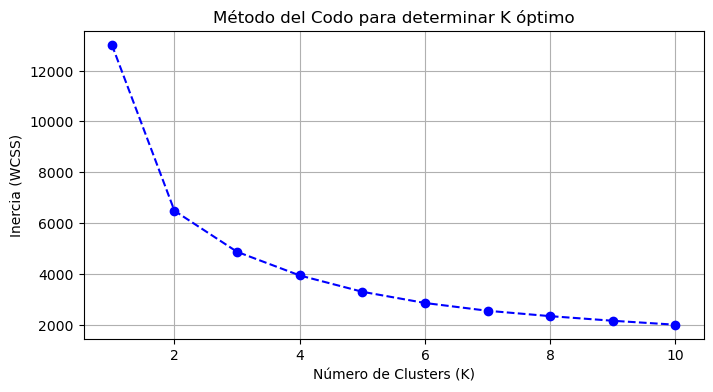

Para K = 2, el Coeficiente de Silueta es: 0.4329
Para K = 3, el Coeficiente de Silueta es: 0.3365
Para K = 4, el Coeficiente de Silueta es: 0.3371
Para K = 5, el Coeficiente de Silueta es: 0.3161
Para K = 6, el Coeficiente de Silueta es: 0.3133
Para K = 7, el Coeficiente de Silueta es: 0.3100
Para K = 8, el Coeficiente de Silueta es: 0.3008
Para K = 9, el Coeficiente de Silueta es: 0.2817
Para K = 10, el Coeficiente de Silueta es: 0.2787


In [ ]:
from sklearn.cluster import KMeans

# Calcular inercia (WCSS) para valores de K entre 1 y 10
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled_df)
    wcss.append(kmeans.inertia_)

# Graficar el Método del Codo
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title('Método del Codo para determinar K óptimo')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inercia (WCSS)')
plt.grid(True)
plt.show()
from sklearn.metrics import silhouette_score

# Calcular Silhouette Score para diferentes valores de K (de 2 a 10)
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(rfm_scaled_df)
    score = silhouette_score(rfm_scaled_df, cluster_labels)
    silhouette_scores.append(score)
    print(f"Para K = {k}, el Coeficiente de Silueta es: {score:.4f}")

In [ ]:
# 1. Entrenar K-Means con 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled_df)

# 2. Promediar las métricas RFM originales por cluster para interpretarlos
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

# Renombrar columnas para facilitar lectura
cluster_summary.columns = ['Recency_Media', 'Frequency_Media', 'Monetary_Media', 'Cantidad_Clientes']
print("--- Perfil promedio de cada Cluster ---")
cluster_summary.sort_values(by='Monetary_Media', ascending=False)

--- Perfil promedio de cada Cluster ---


,Recency_Media,Frequency_Media,Monetary_Media,Cantidad_Clientes
Cluster,,,,
1,12.1,13.7,8074.3,716
2,71.1,4.1,1802.8,1173
0,18.1,2.1,551.8,837
3,182.5,1.3,343.5,1612


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. División Temporal Estricta (Últimos 90 días para test, el resto para train)
max_date = df_clean['InvoiceDate'].max()
threshold_date = max_date - pd.Timedelta(days=90)

train_set = df_clean[df_clean['InvoiceDate'] < threshold_date].copy()
test_set = df_clean[df_clean['InvoiceDate'] >= threshold_date].copy()

print(f"Fecha de corte temporal: {threshold_date}")
print(f"Registros en Train: {len(train_set)} | Registros en Test: {len(test_set)}")

# 2. Matriz Usuario-Producto EXCLUSIVAMENTE con train_set
user_item_matrix = train_set.pivot_table(
    index='CustomerID',
    columns='StockCode',
    values='Quantity',
    aggfunc='sum'
).fillna(0)

user_item_matrix_binary = (user_item_matrix > 0).astype(int)

# 3. Similitud Usuario-Usuario e Ítem-Ítem (con la transpuesta .T)
user_similarity = cosine_similarity(user_item_matrix_binary)
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

item_similarity = cosine_similarity(user_item_matrix_binary.T)
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

print("✅ División temporal y matrices de similitud generadas correctamente.")

Fecha de corte temporal: 2011-09-10 12:50:00
Registros en Train: 236358 | Registros en Test: 161526
✅ División temporal y matrices de similitud generadas correctamente.


In [ ]:
# A. Baseline: Top-Sellers
top_sellers_train = train_set.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False).index.tolist()

def recomendar_top_sellers(customer_id, top_n=5):
    return top_sellers_train[:top_n]


# B. Filtrado Colaborativo Usuario-Usuario
def recomendar_usuario_usuario(customer_id, top_n=5):
    if customer_id not in user_similarity_df.index:
        return recomendar_top_sellers(customer_id, top_n)

    similar_users = user_similarity_df[customer_id].sort_values(ascending=False).iloc[1:6].index
    target_user_products = set(train_set[train_set['CustomerID'] == customer_id]['StockCode'])

    recommended_products = []
    for user in similar_users:
        user_products = set(train_set[train_set['CustomerID'] == user]['StockCode'])
        new_recs = user_products - target_user_products
        recommended_products.extend(list(new_recs))

    if not recommended_products:
        return recomendar_top_sellers(customer_id, top_n)

    recs_series = pd.Series(recommended_products).value_counts().head(top_n)
    return list(recs_series.index)


# C. Filtrado Colaborativo Ítem-Ítem (El obligatorio que faltaba)
def recomendar_item_item(customer_id, top_n=5):
    if customer_id not in user_item_matrix.index:
        return recomendar_top_sellers(customer_id, top_n)

    user_vector = user_item_matrix.loc[customer_id]
    user_bought = set(user_vector[user_vector > 0].index)

    if not user_bought:
        return recomendar_top_sellers(customer_id, top_n)

    item_scores = item_similarity_df[list(user_bought)].sum(axis=1)
    candidate_items = item_scores.drop(labels=list(user_bought), errors='ignore')

    recommended_items = candidate_items.sort_values(ascending=False).head(top_n).index.tolist()

    if len(recommended_items) < top_n:
        for item in top_sellers_train:
            if item not in recommended_items and item not in user_bought:
                recommended_items.append(item)
            if len(recommended_items) == top_n:
                break

    return recommended_items[:top_n]


# --- EVALUACIÓN Y COMPARATIVA FINAL ---
actual_test_purchases = test_set.groupby('CustomerID')['StockCode'].apply(set).to_dict()

def evaluar_modelo_completo(recom_func, k=5):
    precisions, recalls, hits = [], [], 0
    valid_users = 0
    total_users_evaluated = 0

    for cust_id, actual_items in actual_test_purchases.items():
        if len(actual_items) == 0:
            continue
        total_users_evaluated += 1
        recommended_items = recom_func(cust_id, top_n=k)

        if len(recommended_items) > 0:
            valid_users += 1

        recommended_set = set(recommended_items)
        intersect = recommended_set.intersection(actual_items)

        precisions.append(len(intersect) / k)
        recalls.append(len(intersect) / len(actual_items))
        if len(intersect) > 0:
            hits += 1

    precision_mean = np.mean(precisions) if precisions else 0
    recall_mean = np.mean(recalls) if recalls else 0
    hit_rate = hits / total_users_evaluated if total_users_evaluated > 0 else 0
    coverage = valid_users / total_users_evaluated if total_users_evaluated > 0 else 0

    return precision_mean, recall_mean, hit_rate, coverage

p_user, r_user, h_user, c_user = evaluar_modelo_completo(recomendar_usuario_usuario, k=5)
p_item, r_item, h_item, c_item = evaluar_modelo_completo(recomendar_item_item, k=5)
p_base, r_base, h_base, c_base = evaluar_modelo_completo(recomendar_top_sellers, k=5)

results_df = pd.DataFrame({
    'Modelo': ['Usuario-Usuario', 'Ítem-Ítem', 'Top-Sellers (Baseline)'],
    'Precision@5': [p_user, p_item, p_base],
    'Recall@5': [r_user, r_item, r_base],
    'Hit Rate@5': [h_user, h_item, h_base],
    'Cobertura': [c_user, c_item, c_base]
})

print("=== COMPARATIVA FINAL DE MODELOS ===")
print(results_df.to_string(index=False))

=== COMPARATIVA FINAL DE MODELOS ===
                Modelo  Precision@5  Recall@5  Hit Rate@5  Cobertura
       Usuario-Usuario     0.067497  0.012269    0.255106        1.0
             Ítem-Ítem     0.085912  0.015125    0.301142        1.0
Top-Sellers (Baseline)     0.083351  0.014145    0.321565        1.0
